In [2]:
from pathlib import Path
import pandas as pd
import json

# Locate the repository root
ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "data/processed/training_handoff/annual_model_table.csv").exists()),
    None
)

if ROOT is None:
    raise FileNotFoundError("Cannot locate the Posters repository.")

# Load data
df = pd.read_csv(
    ROOT / "data/processed/training_handoff/annual_model_table.csv"
)

# Load predefined feature groups
with open(ROOT / "data/processed/feature_sets_v1.json") as f:
    feature_sets = json.load(f)

# Select the 12 visual features
visual_features = feature_sets["visual_baseline"]

X = df[visual_features]
y = df["y_active_mid_count"]

print("X shape:", X.shape)
print("y shape:", y.shape)

display(df.head())


X shape: (65, 12)
y shape: (65,)


,poster_year,target_year,n_posters,red_ratio_mean,red_ratio_n_valid,red_ratio_missing_ratio,r_mean_mean,r_mean_n_valid,r_mean_missing_ratio,g_mean_mean,...,archive_tag_agriculture_n_valid,archive_tag_agriculture_missing_ratio,archive_tag_mao_mean,archive_tag_mao_n_valid,archive_tag_mao_missing_ratio,archive_tag_red_flag_mean,archive_tag_red_flag_n_valid,archive_tag_red_flag_missing_ratio,y_active_mid_count,split
0,1949,1950,10,0.230524,10,0.0,0.581460,10,0.0,0.425264,...,10,0.0,0.200000,10,0.0,0.200000,10,0.0,6,development
1,1950,1951,26,0.063322,26,0.0,0.719032,26,0.0,0.669839,...,26,0.0,0.192308,26,0.0,0.153846,26,0.0,3,development
2,1951,1952,60,0.074302,60,0.0,0.667969,60,0.0,0.591164,...,60,0.0,0.083333,60,0.0,0.083333,60,0.0,3,development
3,1952,1953,98,0.048475,98,0.0,0.675367,98,0.0,0.610160,...,98,0.0,0.040816,98,0.0,0.051020,98,0.0,5,development
4,1953,1954,116,0.055321,116,0.0,0.634614,116,0.0,0.557587,...,116,0.0,0.051724,116,0.0,0.034483,116,0.0,6,development


count    65.000000
mean      3.400000
std       2.127205
min       0.000000
25%       2.000000
50%       3.000000
75%       5.000000
max      10.000000
Name: y_active_mid_count, dtype: float64


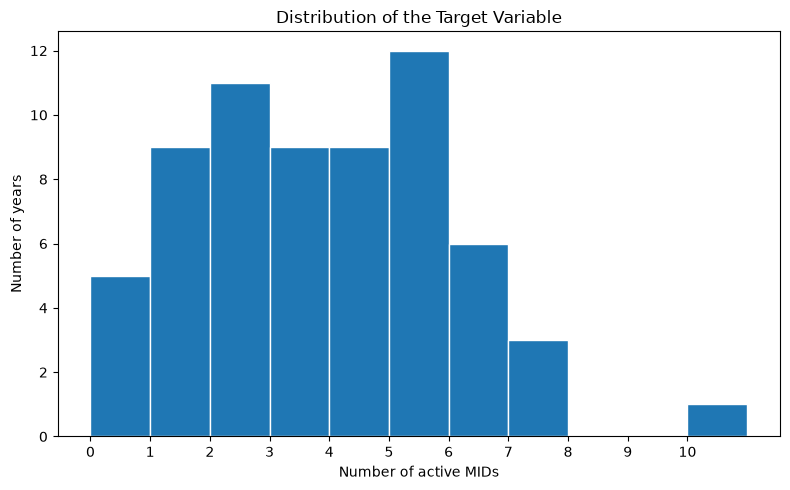

In [4]:
import matplotlib.pyplot as plt

print(y.describe())

plt.figure(figsize=(8, 5))
plt.hist(y, bins=range(12), edgecolor="white")

plt.xlabel("Number of active MIDs")
plt.ylabel("Number of years")
plt.title("Distribution of the Target Variable")
plt.xticks(range(11))
plt.tight_layout()
plt.show()
